# Where the DSMEM workloads sit on the H100 NVL roofline

Every workload of `../workloads/` exists in a version that exchanges data between the CTAs of a thread-block
cluster through distributed shared memory (DSMEM) and in a version that does not. This notebook places both versions
on the roofline of one H100 NVL, measured on the device at a locked SM clock. Inputs: the manifests (`../workloads/*.yaml`),
`../results/ceilings.csv` and `../results/points.csv`; the logic is in `roofline_figures.py`.

In [1]:
import roofline_figures as rf
C = rf.ceilings()

## Setup

In [2]:
rf.table_setup(C)

,
device,"NVIDIA H100 NVL, 132 SMs (GPU 3)"
driver / CUDA,580.126.20 / 12.9
SM clock,locked at 1635 MHz for every timed and ncu run; memory clock 2619 MHz
ceilings run,2026-10-26T15:19:46.084+00:00


## Definitions

| Term | Meaning |
|---|---|
| ceiling | best sustained rate of one resource, measured by a microbenchmark on this GPU at the locked clock (`../harness/ceilings/`) |
| operational intensity | work (FLOP, or integer ops for integer workloads) per byte moved at one memory level; on the classic roofline the level is HBM |
| datasheet at lock | datasheet peak (quoted at the 1785 MHz maximum clock) × 1635 / 1785, the peak the locked clock allows |
| ridge point | intensity at which a compute ceiling meets the HBM slope: below it a kernel cannot be compute-bound |

## 1. The device at 1635 MHz

The roofline below is drawn from measurements only; dotted lines are the datasheet peaks. Each compute roof starts
where it meets the HBM slope; the dashed lines are the bandwidths of the other memory levels, which bound a kernel
that reuses data from them.

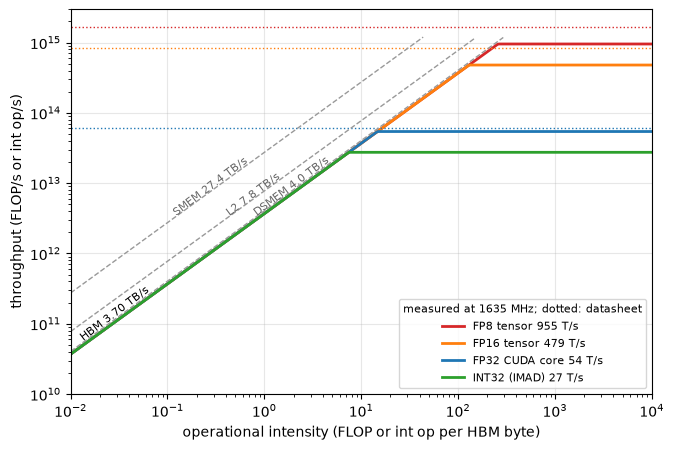

In [3]:
rf.fig_ceilings(C)

In [4]:
rf.table_ceilings(C)

,measured,unit,datasheet,datasheet at lock,measured / datasheet at lock,ridge vs HBM (FLOP/B)
ceiling,,,,,,
FP8 tensor,954.9,TFLOP/s,1670.5,1530.1,62%,258.1
BF16 tensor,526.3,TFLOP/s,835.5,765.3,69%,142.3
FP16 tensor,479.5,TFLOP/s,835.5,765.3,63%,129.6
FP32 CUDA core,54.3,TFLOP/s,60.0,55.0,99%,14.7
INT32 (IMAD),27.5,Tintop/s,—,—,—,7.4
SMEM,27.4,TB/s,—,—,—,—
L2,7.8,TB/s,—,—,—,—
DSMEM,4.0,TB/s,—,—,—,—
HBM,3.7,TB/s,3.9,3.9,95%,—


**Compute.** The FP32 FFMA ceiling reaches 99 % of the datasheet value at the locked clock, so the clock lock and the
measurement are sound. The tensor-core ceilings come from cuBLAS GEMMs of 8192³ and reach 62–69 % of the datasheet
value at the lock: that is what a large library GEMM attains on this card, not the instruction peak. They also only hold
for short bursts. Back-to-back GEMMs drive the card into its 400 W limit and the SM clock falls below the lock
(1605–1620 MHz, once 1485 MHz); the first ceiling run lost 61 of its 100 tensor-core launches to this. The values above
come from launches separated by 1 s of idle time, all at 1635 MHz. Integer IMAD runs at half the FFMA rate (27.5 vs
54.3 T op/s), as the FMA-heavy pipe issues IMAD every other cycle.

**Memory.** HBM reaches 3.70 TB/s read (95 % of the 3.9 TB/s datasheet), L2 7.75 TB/s and shared memory 27.4 TB/s
(128 B per cycle per SM). These are the values microbench experiment 05 measured on GPU 2 of this server, within 1 %.

**DSMEM.** The table below is the aggregate bandwidth when every SM streams to or from a peer in its cluster, with
as many clusters as fit at one CTA per SM.

In [5]:
rf.table_dsmem(C)

,"pull (ld.shared::cluster.v4), TB/s","push (bulk copy), TB/s"
cluster size,,
2,3.54,4.04
4,2.77,3.24
8,2.78,2.93
16,2.59,2.49


The best case, bulk pushes in clusters of 2, reaches 4.04 TB/s, 88 % of the per-SM send limit of the SM-to-SM network
(21.33 B/cycle/SM × 132 SMs × 1.635 GHz = 4.6 TB/s, microbench experiment 11). Larger clusters lose up to 38 %, because
more of the traffic crosses the GPC's shared crossbar. The DSMEM ceiling is therefore only 9 % above the HBM
ceiling and 7× below shared memory: moving data between SMs is not a faster path than reading it from HBM. A DSMEM
port can gain on this roofline in one way only: by moving fewer bytes through HBM (higher intensity), or by replacing
a sequence of kernels whose intermediate results would otherwise make the round trip through memory.